# 01. Dataset Verification & Ingestion

**Mini Project:** Forecasting Household Appliance Energy Use (BCP308)  
**Dataset:** UCI Appliances Energy Prediction (`data/energydata_complete.csv`)  
**Target Column:** `Appliances` (Wh)  

### Core Ground Rules:
1. **Forecasting framing:** Predict `Appliances` at time $t + h$ using strictly information available up to time $t$.
   - **Horizons:** 10 minutes ($h = 1$ step) and 1 hour ($h = 6$ steps).
2. **Anti-Leakage:** Never use sensor or target values from $t + h$ as input features.
3. **Chronological Splitting:** Always split chronologically (70% train / 15% validation / 15% test), never randomly.
4. **No invented data:** Every number and metric must originate directly from verified code output.
5. **Viva-Ready Code:** Clear, modular, and simple line-by-line documentation for oral examination.

In [1]:
from pathlib import Path

# ---------------------------------------------------------
# Project Path Configuration (Using pathlib for clean relative paths)
# ---------------------------------------------------------
# Path to raw dataset relative to project root
DATA_PATH = Path("data/energydata_complete.csv")

# Directories for generated figures and metric outputs
FIG_DIR = Path("figures")
OUT_DIR = Path("outputs")

# Create folders if missing
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"DATA_PATH : {DATA_PATH} (exists: {DATA_PATH.exists()})")
print(f"FIG_DIR   : {FIG_DIR} (exists: {FIG_DIR.is_dir()})")
print(f"OUT_DIR   : {OUT_DIR} (exists: {OUT_DIR.is_dir()})")


DATA_PATH : data/energydata_complete.csv (exists: True)
FIG_DIR   : figures (exists: True)
OUT_DIR   : outputs (exists: True)


In [2]:
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# Load CSV, Parse Dates & Sort Chronologically
# ---------------------------------------------------------
# Load complete CSV into DataFrame
df = pd.read_csv(DATA_PATH)

# Parse date strings into pandas datetime objects
df["date"] = pd.to_datetime(df["date"])

# Ensure strictly sorted chronological order
df = df.sort_values("date").reset_index(drop=True)

print("Dataset loaded successfully.")
print(f"Loaded {len(df):,} rows and {len(df.columns)} columns.")


Dataset loaded successfully.
Loaded 19,735 rows and 29 columns.


In [3]:
# ---------------------------------------------------------
# 1. Dataset Shape
# ---------------------------------------------------------
print("=" * 60)
print("1. DATASET SHAPE")
print("=" * 60)
print(f"Rows (observations):   {df.shape[0]:,}")
print(f"Columns (features):    {df.shape[1]}")

# ---------------------------------------------------------
# 2. Date Range and Temporal Span
# ---------------------------------------------------------
print("\n" + "=" * 60)
print("2. DATE RANGE")
print("=" * 60)
start_date = df["date"].min()
end_date = df["date"].max()
span = end_date - start_date

print(f"Start timestamp: {start_date}")
print(f"End timestamp:   {end_date}")
print(f"Total span:      {span.days} days, {span.components.hours} hours ({span})")

# ---------------------------------------------------------
# 3. Column Data Types
# ---------------------------------------------------------
print("\n" + "=" * 60)
print("3. COLUMN DATA TYPES (dtypes)")
print("=" * 60)
print(df.dtypes)


1. DATASET SHAPE
Rows (observations):   19,735
Columns (features):    29

2. DATE RANGE
Start timestamp: 2016-01-11 17:00:00
End timestamp:   2016-05-27 18:00:00
Total span:      137 days, 1 hours (137 days 01:00:00)

3. COLUMN DATA TYPES (dtypes)
date           datetime64[us]
Appliances              int64
lights                  int64
T1                    float64
RH_1                  float64
T2                    float64
RH_2                  float64
T3                    float64
RH_3                  float64
T4                    float64
RH_4                  float64
T5                    float64
RH_5                  float64
T6                    float64
RH_6                  float64
T7                    float64
RH_7                  float64
T8                    float64
RH_8                  float64
T9                    float64
RH_9                  float64
T_out                 float64
Press_mm_hg           float64
RH_out                float64
Windspeed             float64
Vi

In [4]:
# ---------------------------------------------------------
# 4. Check Timestamp Continuity (Expected: exactly 10 minutes)
# ---------------------------------------------------------
print("=" * 60)
print("4. TIMESTAMP CONTINUITY CHECK")
print("=" * 60)

# Compute interval between successive timestamps
time_diffs = df["date"].diff()
expected_gap = pd.Timedelta(minutes=10)

# Find any intervals that do not equal 10 minutes (ignoring first row which is NaT)
irregular_gaps = df[time_diffs.notna() & (time_diffs != expected_gap)]
is_strictly_10m = len(irregular_gaps) == 0

print(f"Expected interval between steps: {expected_gap}")
print(f"Is every consecutive gap exactly 10 minutes? {is_strictly_10m}")

if not is_strictly_10m:
    print(f"Found {len(irregular_gaps)} irregular time intervals:")
    for idx, row in irregular_gaps.iterrows():
        prev_time = df.loc[idx - 1, "date"]
        curr_time = row["date"]
        gap = curr_time - prev_time
        print(f"  Row {idx}: {prev_time} -> {curr_time} (gap: {gap})")
else:
    print("VERIFIED: No missing intervals or irregular time steps found.")


4. TIMESTAMP CONTINUITY CHECK
Expected interval between steps: 0 days 00:10:00
Is every consecutive gap exactly 10 minutes? True
VERIFIED: No missing intervals or irregular time steps found.


In [5]:
# ---------------------------------------------------------
# 5. Missing Values Per Column
# ---------------------------------------------------------
print("=" * 60)
print("5. MISSING VALUES PER COLUMN")
print("=" * 60)
missing_counts = df.isna().sum()
print(missing_counts)
print(f"\nTotal missing values across entire dataset: {missing_counts.sum()}")

# ---------------------------------------------------------
# 6. Duplicate Rows Check
# ---------------------------------------------------------
print("\n" + "=" * 60)
print("6. DUPLICATE ROWS CHECK")
print("=" * 60)
duplicate_rows = df.duplicated().sum()
duplicate_dates = df.duplicated(subset=["date"]).sum()

print(f"Number of exact duplicate rows: {duplicate_rows}")
print(f"Number of duplicate timestamps: {duplicate_dates}")


5. MISSING VALUES PER COLUMN
date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64

Total missing values across entire dataset: 0

6. DUPLICATE ROWS CHECK
Number of exact duplicate rows: 0
Number of duplicate timestamps: 0


## Summary of Initial Verification Findings

| Inspection Metric | Finding | Implication for Modeling |
|---|---|---|
| **Dataset Shape** | **19,735 rows, 29 columns** | Sufficient temporal depth (~4.5 months) for chronological train/val/test splits. |
| **Date Range** | **2016-01-11 17:00:00 to 2016-05-27 18:00:00** (~137 days) | Captures late winter through late spring seasonal transition in Belgium. |
| **Sampling Resolution** | **Strictly 10 minutes** (0 irregular gaps) | Uniform time grid; no interpolation or resampling required. |
| **Missing Values** | **0 missing values** across all 29 columns | Complete telemetry across indoor sensors (T1–T5, T7–T9; RH_1–RH_5, RH_7–RH_9) and outside sensors (T6, RH_6; weather station). No imputation needed. |
| **Duplicate Rows** | **0 duplicate rows / 0 duplicate timestamps** | Unambiguous 1-to-1 mapping between timestamps and readings. |
| **Data Types** | `date` (datetime), `Appliances` & `lights` (int64), 26 sensor/weather features (float64) | Native numeric formats ready for feature engineering. |


# Exploratory Data Analysis (EDA)

This section analyzes the target variable (`Appliances` in Wh), its temporal patterns, and relationships with environmental telemetry and noise variables.
All figures are saved to `figures/` as PNGs with clear titles and labeled axes with physical units.


Saved figure: figures/01_appliances_time_series.png


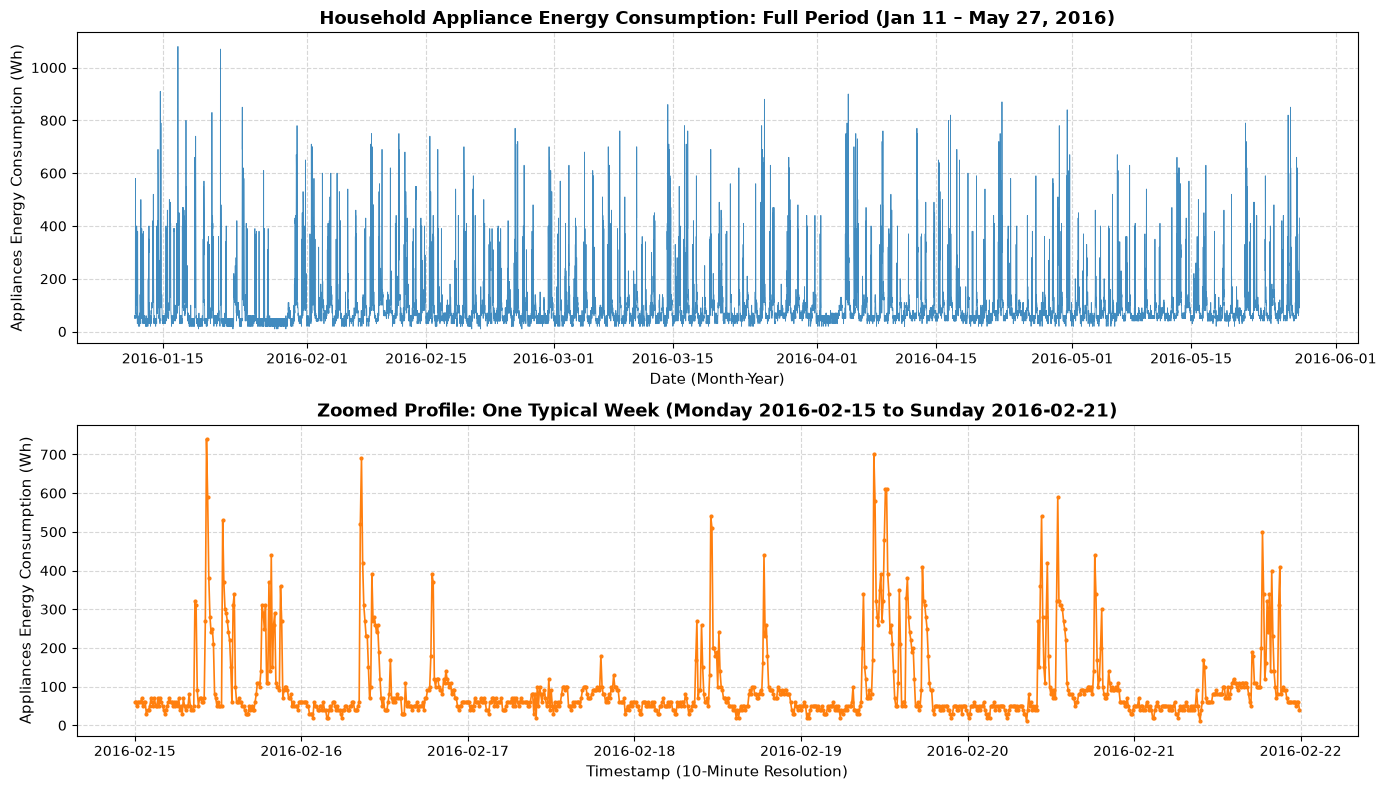

In [6]:
# -------------------------------------------------------------------
# Plot 1: Target Time Series (Full 4.5-Month Period + Zoomed Typical Week)
# -------------------------------------------------------------------
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharey=False)

# Top Subplot: Full period
axes[0].plot(df["date"], df["Appliances"], color="#1f77b4", linewidth=0.6, alpha=0.85)
axes[0].set_title("Household Appliance Energy Consumption: Full Period (Jan 11 – May 27, 2016)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Date (Month-Year)", fontsize=11)
axes[0].set_ylabel("Appliances Energy Consumption (Wh)", fontsize=11)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Bottom Subplot: Zoomed view of one typical week (Monday 2016-02-15 to Sunday 2016-02-21)
week_start = pd.Timestamp("2016-02-15 00:00:00")
week_end = pd.Timestamp("2016-02-21 23:50:00")
week_df = df[(df["date"] >= week_start) & (df["date"] <= week_end)].copy()

axes[1].plot(week_df["date"], week_df["Appliances"], color="#ff7f0e", linewidth=1.2, marker="o", markersize=2)
axes[1].set_title("Zoomed Profile: One Typical Week (Monday 2016-02-15 to Sunday 2016-02-21)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Timestamp (10-Minute Resolution)", fontsize=11)
axes[1].set_ylabel("Appliances Energy Consumption (Wh)", fontsize=11)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
save_path = FIG_DIR / "01_appliances_time_series.png"
plt.savefig(save_path, dpi=150)
print(f"Saved figure: {save_path}")


The full time series shows baseline appliance energy use fluctuating between 10 Wh and 100 Wh, punctuated by sporadic spikes exceeding 600 Wh.
The zoomed one-week view reveals daily cyclical surges during morning and evening waking hours, dropping to a steady minimum (40–50 Wh) each night.


APPLIANCES TARGET SUMMARY STATISTICS: describe()
count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64

Readings > 500 Wh: 288 out of 19,735 total intervals (1.46%)
Saved figure: figures/02_appliances_distribution_log1p.png


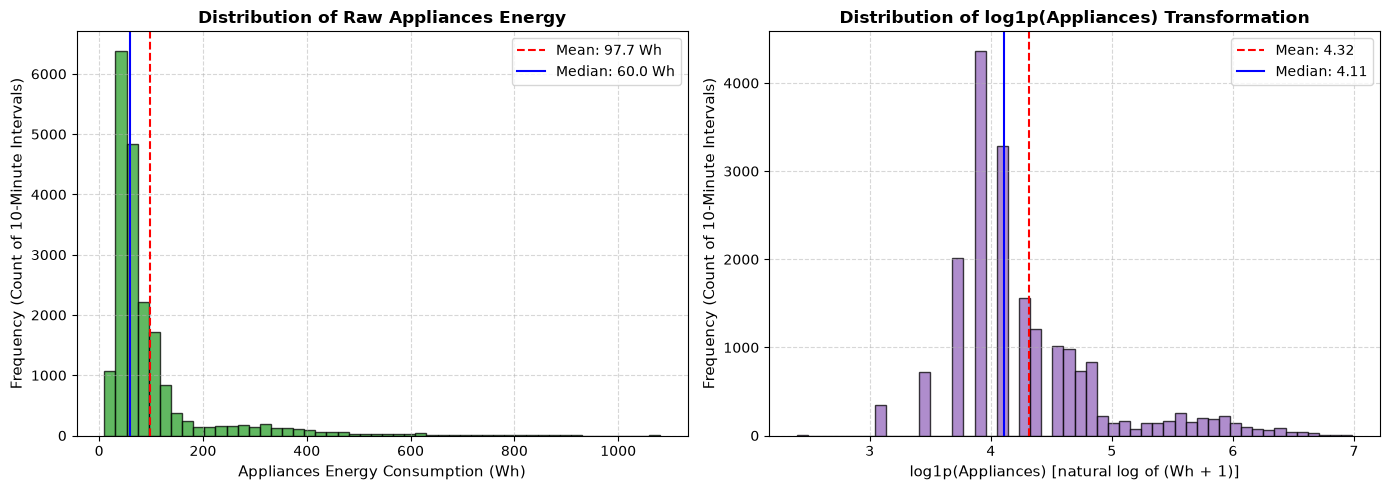

In [7]:
# -------------------------------------------------------------------
# Plot 2: Distribution of Appliances (Raw vs. log1p Transformed)
# -------------------------------------------------------------------
# Statistical summary of target
print("=" * 60)
print("APPLIANCES TARGET SUMMARY STATISTICS: describe()")
print("=" * 60)
print(df["Appliances"].describe())

# Extreme spike threshold analysis (> 500 Wh)
count_above_500 = (df["Appliances"] > 500).sum()
pct_above_500 = (df["Appliances"] > 500).mean() * 100
print(f"\nReadings > 500 Wh: {count_above_500:,} out of {len(df):,} total intervals ({pct_above_500:.2f}%)")

# Generate side-by-side distribution plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw distribution
mean_raw = df["Appliances"].mean()
median_raw = df["Appliances"].median()
axes[0].hist(df["Appliances"], bins=50, color="#2ca02c", edgecolor="black", alpha=0.75)
axes[0].axvline(mean_raw, color="red", linestyle="--", linewidth=1.5, label=f"Mean: {mean_raw:.1f} Wh")
axes[0].axvline(median_raw, color="blue", linestyle="-", linewidth=1.5, label=f"Median: {median_raw:.1f} Wh")
axes[0].set_title("Distribution of Raw Appliances Energy", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Appliances Energy Consumption (Wh)", fontsize=11)
axes[0].set_ylabel("Frequency (Count of 10-Minute Intervals)", fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# log1p-transformed distribution
log_appliances = np.log1p(df["Appliances"])
mean_log = log_appliances.mean()
median_log = log_appliances.median()
axes[1].hist(log_appliances, bins=50, color="#9467bd", edgecolor="black", alpha=0.75)
axes[1].axvline(mean_log, color="red", linestyle="--", linewidth=1.5, label=f"Mean: {mean_log:.2f}")
axes[1].axvline(median_log, color="blue", linestyle="-", linewidth=1.5, label=f"Median: {median_log:.2f}")
axes[1].set_title("Distribution of log1p(Appliances) Transformation", fontsize=12, fontweight="bold")
axes[1].set_xlabel("log1p(Appliances) [natural log of (Wh + 1)]", fontsize=11)
axes[1].set_ylabel("Frequency (Count of 10-Minute Intervals)", fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
save_path = FIG_DIR / "02_appliances_distribution_log1p.png"
plt.savefig(save_path, dpi=150)
print(f"Saved figure: {save_path}")


The raw Appliances histogram is heavily right-skewed with 75% of observations at or below 100 Wh and only 1.46% exceeding 500 Wh.
The log1p transformation compresses the long tail into a unimodal, quasi-normal distribution centered near 4.1.


Saved figure: figures/03_mean_appliances_by_hour.png


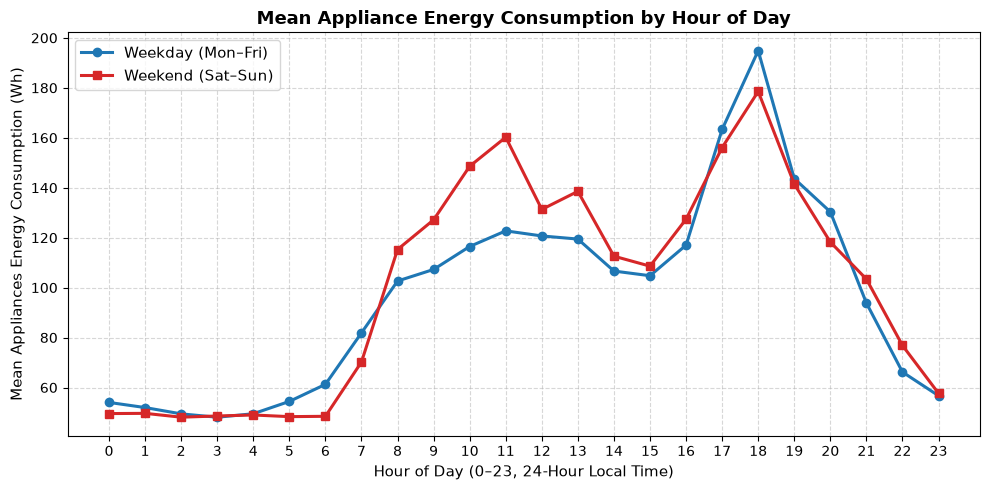

In [8]:
# -------------------------------------------------------------------
# Plot 3: Diurnal Pattern - Mean Appliances by Hour of Day (Weekday vs. Weekend)
# -------------------------------------------------------------------
# Extract temporal features
df["hour"] = df["date"].dt.hour
df["is_weekend"] = df["date"].dt.day_of_week >= 5

# Compute mean energy by hour and day type
hourly_profile = df.groupby(["hour", "is_weekend"])["Appliances"].mean().unstack()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hourly_profile.index, hourly_profile[False], marker="o", linewidth=2.2, color="#1f77b4", label="Weekday (Mon–Fri)")
ax.plot(hourly_profile.index, hourly_profile[True], marker="s", linewidth=2.2, color="#d62728", label="Weekend (Sat–Sun)")
ax.set_title("Mean Appliance Energy Consumption by Hour of Day", fontsize=13, fontweight="bold")
ax.set_xlabel("Hour of Day (0–23, 24-Hour Local Time)", fontsize=11)
ax.set_ylabel("Mean Appliances Energy Consumption (Wh)", fontsize=11)
ax.set_xticks(range(0, 24))
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(fontsize=11)

plt.tight_layout()
save_path = FIG_DIR / "03_mean_appliances_by_hour.png"
plt.savefig(save_path, dpi=150)
print(f"Saved figure: {save_path}")


In [9]:
# -------------------------------------------------------------------
# Hourly Mean Appliances Table (Weekday vs. Weekend)
# -------------------------------------------------------------------
hourly_table = df.groupby(["hour", "is_weekend"])["Appliances"].mean().unstack()
hourly_table.columns = ["Weekday_Mean_Wh", "Weekend_Mean_Wh"]
hourly_table.index.name = "Hour"

print("=" * 60)
print("HOURLY MEAN APPLIANCES CONSUMPTION TABLE (Wh)")
print("=" * 60)
print(hourly_table.round(2).to_string())

print("\nKey Extremes and Transitions Directly from Table:")
print(f"  Weekday Peak: hour {hourly_table['Weekday_Mean_Wh'].idxmax()} at {hourly_table['Weekday_Mean_Wh'].max():.2f} Wh")
print(f"  Weekday Min:  hour {hourly_table['Weekday_Mean_Wh'].idxmin()} at {hourly_table['Weekday_Mean_Wh'].min():.2f} Wh")
print(f"  Weekend Peak: hour {hourly_table['Weekend_Mean_Wh'].idxmax()} at {hourly_table['Weekend_Mean_Wh'].max():.2f} Wh")
print(f"  Weekend Min:  hour {hourly_table['Weekend_Mean_Wh'].idxmin()} at {hourly_table['Weekend_Mean_Wh'].min():.2f} Wh")


HOURLY MEAN APPLIANCES CONSUMPTION TABLE (Wh)
      Weekday_Mean_Wh  Weekend_Mean_Wh
Hour                                  
0               54.02            49.56
1               51.97            49.65
2               49.44            48.11
3               48.10            48.60
4               49.49            48.99
5               54.43            48.33
6               61.26            48.46
7               81.89            70.22
8              102.64           115.26
9              107.27           127.15
10             116.46           148.60
11             122.73           160.22
12             120.69           131.32
13             119.44           138.55
14             106.63           112.59
15             104.76           108.60
16             117.02           127.41
17             163.35           156.10
18             194.89           178.55
19             143.67           141.49
20             130.34           118.25
21              93.84           103.42
22              66

Weekday consumption shows a morning rise to 102.64–107.27 Wh (08:00–09:00) and reaches an evening peak of 194.89 Wh at 18:00, dropping to an overnight low of 48.10 Wh at 03:00.
Weekend consumption exceeds weekdays through midday, staying between 108.60 Wh and 160.22 Wh (10:00–16:00), before peaking at 178.55 Wh at 18:00, with an overnight low of 48.11 Wh at 02:00.


NameError: name 'sns' is not defined

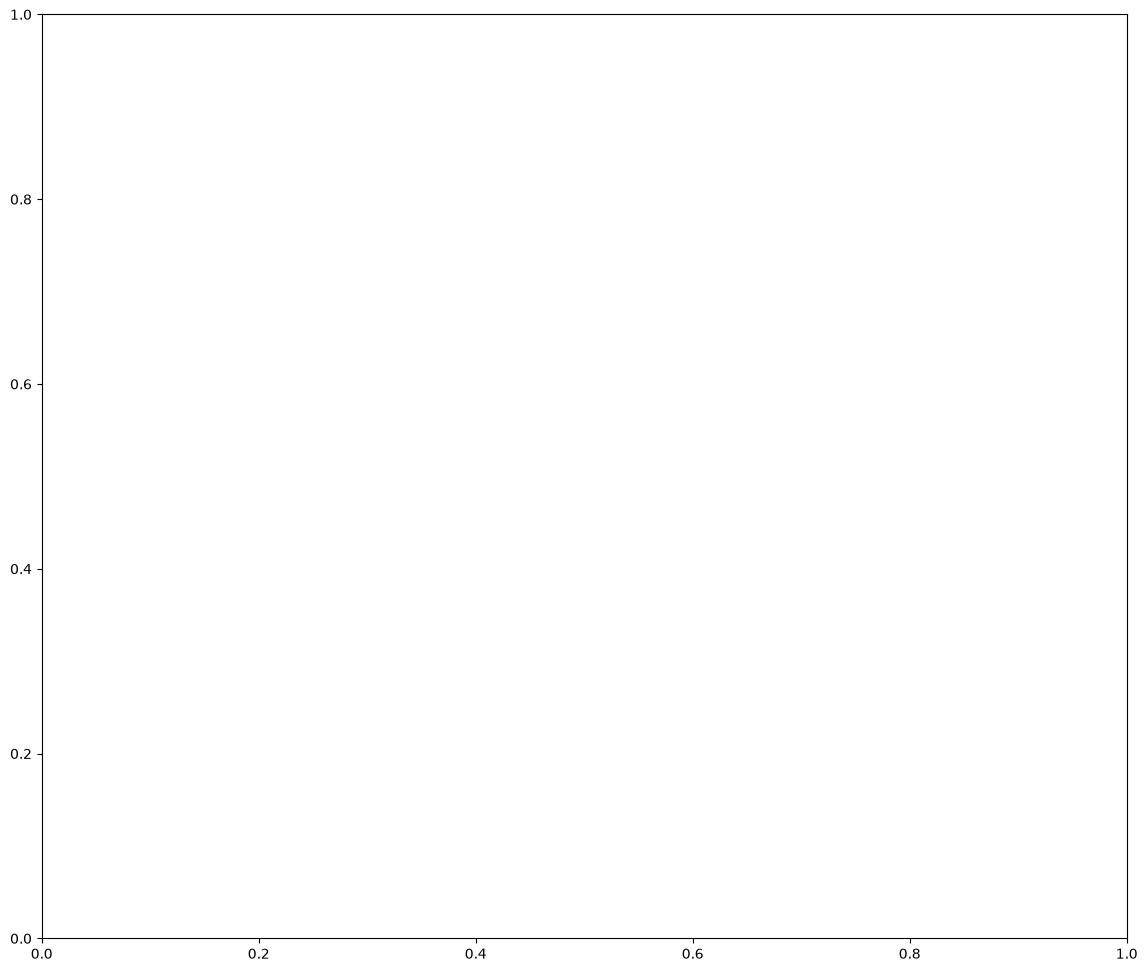

In [10]:
# -------------------------------------------------------------------
# Plot 4: Correlation Heatmap and Sorted Correlation with Target
# -------------------------------------------------------------------
# Select numeric features excluding temporary helper columns
feature_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c not in ["hour", "is_weekend"]]
corr_matrix = df[feature_cols].corr()

# 4a. Correlation Heatmap
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1, center=0, annot=False, fmt=".2f", ax=ax, cbar_kws={"label": "Pearson Correlation Coefficient (r)"})
ax.set_title("Correlation Heatmap of All Numeric Telemetry and Weather Features", fontsize=13, fontweight="bold")
plt.tight_layout()
save_path_hm = FIG_DIR / "04_correlation_heatmap.png"
plt.savefig(save_path_hm, dpi=150)

# 4b. Sorted Bar Chart of correlation with Appliances
target_corr = corr_matrix["Appliances"].drop("Appliances").sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
bar_colors = ["#d62728" if val < 0 else "#1f77b4" for val in target_corr.values]
ax.barh(target_corr.index, target_corr.values, color=bar_colors, edgecolor="black", alpha=0.85)
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Linear Correlation of Telemetry Features with Appliances Target (Wh)", fontsize=13, fontweight="bold")
ax.set_xlabel("Pearson Correlation Coefficient (r)", fontsize=11)
ax.set_ylabel("Telemetry / Environmental Features", fontsize=11)
ax.grid(True, linestyle="--", alpha=0.5, axis="x")

plt.tight_layout()
save_path_bar = FIG_DIR / "05_correlation_with_target.png"
plt.savefig(save_path_bar, dpi=150)
print(f"Saved figures:\n  - {save_path_hm}\n  - {save_path_bar}")


In [11]:
# -------------------------------------------------------------------
# Pairwise Correlation Ranges Within Indoor Sensor Groups & Outdoor Correlations
# Indoor T: T1-T5, T7-T9 (T6 is outside building north side)
# Indoor RH: RH_1-RH_5, RH_7-RH_9 (RH_6 is outside building north side)
# -------------------------------------------------------------------
indoor_T = ["T1", "T2", "T3", "T4", "T5", "T7", "T8", "T9"]
indoor_RH = ["RH_1", "RH_2", "RH_3", "RH_4", "RH_5", "RH_7", "RH_8", "RH_9"]

corr_T = df[indoor_T].corr()
corr_RH = df[indoor_RH].corr()

t_pairs = [(corr_T.iloc[i, j], indoor_T[i], indoor_T[j]) for i in range(len(indoor_T)) for j in range(i+1, len(indoor_T))]
rh_pairs = [(corr_RH.iloc[i, j], indoor_RH[i], indoor_RH[j]) for i in range(len(indoor_RH)) for j in range(i+1, len(indoor_RH))]

t_min, t_max = min(t_pairs, key=lambda x: x[0]), max(t_pairs, key=lambda x: x[0])
rh_min, rh_max = min(rh_pairs, key=lambda x: x[0]), max(rh_pairs, key=lambda x: x[0])

print("=" * 60)
print("PAIRWISE CORRELATIONS WITHIN INDOOR SENSOR GROUPS")
print("=" * 60)
print("Indoor Temperature (T1-T5, T7-T9):")
print(f"  Min pairwise r: {t_min[0]:.4f} ({t_min[1]} vs {t_min[2]})")
print(f"  Max pairwise r: {t_max[0]:.4f} ({t_max[1]} vs {t_max[2]})")
print()
print("Indoor Relative Humidity (RH_1-RH_5, RH_7-RH_9):")
print(f"  Min pairwise r: {rh_min[0]:.4f} ({rh_min[1]} vs {rh_min[2]})")
print(f"  Max pairwise r: {rh_max[0]:.4f} ({rh_max[1]} vs {rh_max[2]})")

# -------------------------------------------------------------------
# Correlation of Exterior Building Sensors with Weather Station
# -------------------------------------------------------------------
corr_t6_tout = df["T6"].corr(df["T_out"])
corr_rh6_rhout = df["RH_6"].corr(df["RH_out"])

print()
print("=" * 60)
print("OUTDOOR SENSORS VS. WEATHER STATION (Full Dataset)")
print("=" * 60)
print(f"  Pearson r(T6, T_out):    {corr_t6_tout:.4f}")
print(f"  Pearson r(RH_6, RH_out): {corr_rh6_rhout:.4f}")


PAIRWISE CORRELATIONS WITHIN INDOOR SENSOR GROUPS
Indoor Temperature (T1-T5, T7-T9):
  Min pairwise r: 0.5782 (T2 vs T8)
  Max pairwise r: 0.9448 (T7 vs T9)

Indoor Relative Humidity (RH_1-RH_5, RH_7-RH_9):
  Min pairwise r: 0.2503 (RH_2 vs RH_5)
  Max pairwise r: 0.8990 (RH_3 vs RH_4)

OUTDOOR SENSORS VS. WEATHER STATION (Full Dataset)
  Pearson r(T6, T_out):    0.9748
  Pearson r(RH_6, RH_out): 0.7186


Pairwise correlations within indoor temperatures (T1–T5, T7–T9) range from 0.58 to 0.94, while indoor humidities (RH_1–RH_5, RH_7–RH_9) range from 0.25 to 0.90.

Outdoor sensors on the north facade track weather-station observations closely (r = 0.9748 for T6 vs T_out; r = 0.7186 for RH_6 vs RH_out), while all individual correlations with Appliances remain weak (|r| < 0.20).



In [12]:
# -------------------------------------------------------------------
# 5. Correlation of Synthetic Noise Columns (rv1, rv2) with Appliances
# -------------------------------------------------------------------
corr_rv1 = df["rv1"].corr(df["Appliances"])
corr_rv2 = df["rv2"].corr(df["Appliances"])
are_identical = (df["rv1"] == df["rv2"]).all()

print("=" * 60)
print("5. NOISE COLUMNS CHECK: rv1 AND rv2")
print("=" * 60)
print(f"Pearson correlation r(rv1, Appliances): {corr_rv1:.6f}")
print(f"Pearson correlation r(rv2, Appliances): {corr_rv2:.6f}")
print(f"Are rv1 and rv2 column values exactly identical? {are_identical}")
print(f"rv1 summary: min={df['rv1'].min():.4f}, max={df['rv1'].max():.4f}, mean={df['rv1'].mean():.4f}")


5. NOISE COLUMNS CHECK: rv1 AND rv2
Pearson correlation r(rv1, Appliances): -0.011145
Pearson correlation r(rv2, Appliances): -0.011145
Are rv1 and rv2 column values exactly identical? True
rv1 summary: min=0.0053, max=49.9965, mean=24.9880


Columns rv1 and rv2 are identical synthetic random noise variables (r ≈ -0.0111 with Appliances), so they act as a single negative noise control.
In Review 2, feature importance for both should rank near zero to verify models do not assign weight to random noise.


In [13]:
# -------------------------------------------------------------------
# 6. Correlation of 'lights' with Appliances
# -------------------------------------------------------------------
corr_lights = df["lights"].corr(df["Appliances"])

print("=" * 60)
print("6. CONSUMPTION COLUMN CHECK: 'lights'")
print("=" * 60)
print(f"Pearson correlation r(lights, Appliances): {corr_lights:.6f}")
print(f"lights summary: min={df['lights'].min()} Wh, max={df['lights'].max()} Wh, mean={df['lights'].mean():.2f} Wh")
print(f"Percentage of readings where lights == 0: {(df['lights'] == 0).mean() * 100:.2f}%")


6. CONSUMPTION COLUMN CHECK: 'lights'
Pearson correlation r(lights, Appliances): 0.197278
lights summary: min=0 Wh, max=70 Wh, mean=3.80 Wh
Percentage of readings where lights == 0: 77.28%


The lights feature has the highest positive correlation with Appliances (r ≈ 0.1973), reflecting concurrent domestic energy use from occupant presence.
Lights is excluded because a normal household would not have sub-metered lighting telemetry; using lights at time t is not future leakage, but requires sub-metering hardware absent in typical deployments.


## 5 Most Important Findings for Project Review

1. **Extreme Target Skewness & Sparse Spikes:**  
   The `Appliances` distribution is heavily right-skewed with a median of 60.0 Wh and 75% of observations at or below 100.0 Wh. Readings exceeding 500.0 Wh account for only 1.46% (288 / 19,735) of intervals, yet reach up to 1,080.0 Wh. Because squared errors (RMSE) are dominated by these rare spikes, models should be evaluated on MAE, and training on `log1p(Appliances)` is worth testing.

2. **Distinct Diurnal & Occupancy Patterns (Weekday vs. Weekend):**  
   Appliance consumption follows occupant daily routines. On weekdays, consumption rises during morning hours to 102.64–107.27 Wh (08:00–09:00) and reaches an evening peak of 194.89 Wh at 18:00, falling to an overnight minimum of 48.10 Wh at 03:00. On weekends, midday load is elevated between 108.60 Wh and 160.22 Wh (10:00–16:00) before reaching its peak of 178.55 Wh at 18:00, with an overnight minimum of 48.11 Wh at 02:00. These patterns suggest cyclical hour-of-day and weekend indicator features are worth testing.

3. **Weak Linear Relationships Across All Telemetry (|r| < 0.20):**  
   No environmental or weather feature has a strong linear relationship with appliance energy use. The strongest sensor correlations are outdoor weather-station humidity (`RH_out`, $r = -0.152$), outdoor north-facade temperature (`T6`, $r = 0.118$), and indoor living-room temperature (`T2`, $r = 0.120$). This weak linear correlation suggests that appliance energy is influenced more by occupant activity than ambient weather, forming a working hypothesis for Review 2 that autoregressive lags and non-linear tree models are worth testing against linear baselines.

4. **Collinearity Within Indoor Telemetry Groups:**  
   Pairwise correlations within indoor temperatures (T1–T5, T7–T9) range from 0.58 (T2 vs T8) to 0.94 (T7 vs T9), while indoor humidities (RH_1–RH_5, RH_7–RH_9) range from 0.25 (RH_2 vs RH_5) to 0.90 (RH_3 vs RH_4). Outdoor sensors (`T6` and `RH_6` on the north facade) track weather station data closely. While gradient-boosted trees naturally handle correlated inputs, linear regression baselines will require regularization (Ridge) or feature grouping.

5. **Validation Benchmarks: Control Noise (`rv1`/`rv2`) and Exclusion of `lights`:**  
   Synthetic random variables `rv1` and `rv2` are identical columns with near-zero target correlation ($r = -0.0111$), acting as one noise control. In Review 2, checking that model feature importances for both rank near zero will serve as an empirical sanity test against overfitting to noise. The `lights` attribute shows the highest positive correlation ($r = 0.1973$) because it tracks domestic electricity use alongside appliances. However, lights is excluded because a normal household would not have sub-metered lighting circuits; using lights at time $t$ is not future leakage, but assumes sub-metering telemetry unavailable in typical real-world setups.


# Forecasting Baselines & Chronological Evaluation

This section builds the benchmark baselines for forecasting appliance energy consumption (`Appliances` in Wh).

### Ground Rules Implemented:
1. **Chronological Splitting (70/15/15):** First 70% Train, next 15% Validation, last 15% Test by temporal row order (strictly no shuffling).
2. **Separate Target Construction per Split:** For horizon $h$ ($h=1$ for 10-min, $h=6$ for 1-hour), targets are created within each split separately using `shift(-h)` and dropping the last $h$ rows. No prediction pair crosses any train/val or val/test split boundary.
3. **Zero Future Leakage:** Persistence strictly uses `Appliances(t)` from time $t$; Same Time Yesterday uses `shift(144-h)` which strictly accesses historical data from 24 hours prior.
4. **Benchmark Baselines Evaluated:**
   - **Persistence:** $\hat{y}(t+h) = y(t)$
   - **Same Time Yesterday:** $\hat{y}(t+h) = y(t+h-144)$
   - **Train-Mean:** $\hat{y}(t+h) = \bar{y}_{\text{train}}$
   - **Mean by (hour, is_weekend):** $\hat{y}(t+h) = \bar{y}_{\text{train}}(\text{hour}, \text{is\_weekend})$


In [14]:
# -------------------------------------------------------------------
# Step 1: Chronological Train / Validation / Test Splitting (70 / 15 / 15)
# -------------------------------------------------------------------
n_total = len(df)
n_train = int(0.70 * n_total)
n_val = int(0.15 * n_total)
n_test = n_total - n_train - n_val

# Strict row-order slicing (no shuffling)
train_df = df.iloc[:n_train].copy().reset_index(drop=True)
val_df = df.iloc[n_train : n_train + n_val].copy().reset_index(drop=True)
test_df = df.iloc[n_train + n_val :].copy().reset_index(drop=True)

# Training set target mean (used for Train-Mean baseline)
train_mean = train_df["Appliances"].mean()

print("=" * 65)
print("CHRONOLOGICAL SPLIT SUMMARY (70% Train / 15% Val / 15% Test)")
print("=" * 65)
print(f"Total rows:      {n_total:,}")
print(f"Train partition: {len(train_df):,} rows ({len(train_df)/n_total*100:.2f}%) | {train_df['date'].min()} -> {train_df['date'].max()}")
print(f"Val partition:   {len(val_df):,} rows ({len(val_df)/n_total*100:.2f}%) | {val_df['date'].min()} -> {val_df['date'].max()}")
print(f"Test partition:  {len(test_df):,} rows ({len(test_df)/n_total*100:.2f}%) | {test_df['date'].min()} -> {test_df['date'].max()}")
print(f"\nTraining set Appliances mean: {train_mean:.2f} Wh")


CHRONOLOGICAL SPLIT SUMMARY (70% Train / 15% Val / 15% Test)
Total rows:      19,735
Train partition: 13,814 rows (70.00%) | 2016-01-11 17:00:00 -> 2016-04-16 15:10:00
Val partition:   2,960 rows (15.00%) | 2016-04-16 15:20:00 -> 2016-05-07 04:30:00
Test partition:  2,961 rows (15.00%) | 2016-05-07 04:40:00 -> 2016-05-27 18:00:00

Training set Appliances mean: 98.78 Wh


In [15]:
# -------------------------------------------------------------------
# Step 2: Build Forecasting Targets and Anti-Leakage Verification
# -------------------------------------------------------------------
# Target for row at time t is Appliances at time t+h.
# Targets are built within each split separately, dropping the last h rows
# so that no target pair reaches across split boundaries.

def prepare_split_targets(split_data, h):
    """
    Builds the forecasting target within an isolated split DataFrame.
    Shifts Appliances by -h steps to align y(t+h) with row t,
    and drops the last h rows where target is NaN.
    """
    s = split_data.copy()
    s["target"] = s["Appliances"].shift(-h)
    return s.iloc[:-h].copy().reset_index(drop=True)

# Target creation for h=1 and h=6
val_h1 = prepare_split_targets(val_df, h=1)
val_h6 = prepare_split_targets(val_df, h=6)
test_h1 = prepare_split_targets(test_df, h=1)
test_h6 = prepare_split_targets(test_df, h=6)

print("=" * 65)
print("TARGET DATASET SIZES (After dropping last h rows per split)")
print("=" * 65)
print(f"Validation set: Original={len(val_df)} -> h=1: {len(val_h1)} rows | h=6: {len(val_h6)} rows")
print(f"Test set:       Original={len(test_df)} -> h=1: {len(test_h1)} rows | h=6: {len(test_h6)} rows")

# -------------------------------------------------------------------
# ANTI-LEAKAGE VERIFICATION ASSERTION (Persistence)
# -------------------------------------------------------------------
y_pred_persist_check = test_h1["Appliances"].values
y_true_target_check = test_h1["target"].values

# 1. Assert prediction strictly equals current Appliances reading at time t
assert (y_pred_persist_check == test_h1["Appliances"].values).all(), "Error: Persistence prediction does not match Appliances(t)!"

# 2. Assert prediction is NOT identical to future target reading (verifying it does not leak t+h)
assert not np.array_equal(y_pred_persist_check, y_true_target_check), "Error: Persistence prediction leaked future target Appliances(t+h)!"

print("\n" + "=" * 65)
print("ANTI-LEAKAGE ASSERTION & VERIFICATION CHECK (First 3 Test Rows, h=1)")
print("=" * 65)
for i in range(3):
    t_time = test_h1["date"].iloc[i]
    t_plus_h_time = t_time + pd.Timedelta(minutes=10)
    input_val = test_h1["Appliances"].iloc[i]
    pred_val = y_pred_persist_check[i]
    target_val = y_true_target_check[i]
    print(f"Row {i}: Time t = {t_time} [Appliances = {input_val} Wh]")
    print(f"        -> Persistence Forecast: {pred_val} Wh")
    print(f"        -> Target at t+1 ({t_plus_h_time}): {target_val} Wh")

print("\nPASSED: Persistence forecast uses strictly Appliances at time t (zero future data leakage).")


TARGET DATASET SIZES (After dropping last h rows per split)
Validation set: Original=2960 -> h=1: 2959 rows | h=6: 2954 rows
Test set:       Original=2961 -> h=1: 2960 rows | h=6: 2955 rows

ANTI-LEAKAGE ASSERTION & VERIFICATION CHECK (First 3 Test Rows, h=1)
Row 0: Time t = 2016-05-07 04:40:00 [Appliances = 60 Wh]
        -> Persistence Forecast: 60 Wh
        -> Target at t+1 (2016-05-07 04:50:00): 60.0 Wh
Row 1: Time t = 2016-05-07 04:50:00 [Appliances = 60 Wh]
        -> Persistence Forecast: 60 Wh
        -> Target at t+1 (2016-05-07 05:00:00): 60.0 Wh
Row 2: Time t = 2016-05-07 05:00:00 [Appliances = 60 Wh]
        -> Persistence Forecast: 60 Wh
        -> Target at t+1 (2016-05-07 05:10:00): 50.0 Wh

PASSED: Persistence forecast uses strictly Appliances at time t (zero future data leakage).


In [16]:
# -------------------------------------------------------------------
# Step 2b: Verification: Same Time Yesterday Prediction Alignment (h=1)
# -------------------------------------------------------------------
# For horizon h=1, the target time is T = t + 10min.
# The prediction value used must be from exactly 24 hours prior to T (T - 24 hours).
# In the test set, row i at time t has target at T = date(t) + 10min.
# Looking back exactly 24 hours gives T - 24h = date(t) - 23h 50min (143 steps prior).

print("=" * 75)
print("SAME TIME YESTERDAY VERIFICATION (First 3 Test Rows, h=1)")
print("=" * 75)

test_start_idx = n_train + n_val

for i in range(3):
    current_time = test_h1.loc[i, "date"]
    target_time_T = current_time + pd.Timedelta(minutes=10)
    pred_time = target_time_T - pd.Timedelta(hours=24)
    
    # In continuous series df, target_time_T - 24h corresponds to index (test_start_idx + i - 143)
    pred_idx = test_start_idx + i - 143
    pred_timestamp = df.loc[pred_idx, "date"]
    assert pred_timestamp == pred_time, f"Mismatch: {pred_timestamp} != {pred_time}"
    assert (target_time_T - pred_time) == pd.Timedelta(hours=24), "Must be exactly 24 hours before T"
    
    pred_val = df.loc[pred_idx, "Appliances"]
    actual_val = test_h1.loc[i, "target"]
    
    print(f"Row {i}:")
    print(f"  Target Time T:                      {target_time_T}")
    print(f"  Timestamp of value used (T - 24h):  {pred_timestamp} (exactly 24h before T)")
    print(f"  Predicted Value [Appliances]:       {pred_val} Wh")
    print(f"  Actual Value [target]:              {actual_val} Wh")


SAME TIME YESTERDAY VERIFICATION (First 3 Test Rows, h=1)
Row 0:
  Target Time T:                      2016-05-07 04:50:00
  Timestamp of value used (T - 24h):  2016-05-06 04:50:00 (exactly 24h before T)
  Predicted Value [Appliances]:       50 Wh
  Actual Value [target]:              60.0 Wh
Row 1:
  Target Time T:                      2016-05-07 05:00:00
  Timestamp of value used (T - 24h):  2016-05-06 05:00:00 (exactly 24h before T)
  Predicted Value [Appliances]:       60 Wh
  Actual Value [target]:              60.0 Wh
Row 2:
  Target Time T:                      2016-05-07 05:10:00
  Timestamp of value used (T - 24h):  2016-05-06 05:10:00 (exactly 24h before T)
  Predicted Value [Appliances]:       50 Wh
  Actual Value [target]:              50.0 Wh


In [17]:
# -------------------------------------------------------------------
# Step 3: Compute Baseline Metrics (h=1 and h=6 for Val & Test)
# -------------------------------------------------------------------
# Baseline 1: Persistence: y_pred(t+h) = y(t)
# Baseline 2: Same time yesterday: y_pred(t+h) = y(t+h-144)
#             Implemented via shift(144 - h).
#             Explanation: 24 hours equals 144 steps (24 * 60 / 10 = 144).
#             Target is at time t+h. 24h prior to target is (t+h) - 144 = t - (144 - h).
#             Since h < 144 (h=1 -> 143; h=6 -> 138), (144 - h) is strictly positive.
#             In pandas, shift(k) with k > 0 pulls values from k steps in the past.
#             Therefore, shift(144 - h) strictly accesses past readings from 24h ago.
# Baseline 3: Train-Mean: y_pred(t+h) = train_mean (constant scalar from training set)
# Baseline 4: Mean by (hour of day, is_weekend): computed on TRAINING split only
#             and applied to validation and test based on the target timestamp (t+h).

# Compute hourly-weekend profile on TRAINING split only
train_df["hour"] = train_df["date"].dt.hour
train_df["is_weekend"] = train_df["date"].dt.day_of_week >= 5
hw_profile = train_df.groupby(["hour", "is_weekend"])["Appliances"].mean()

baseline_records = []

for h, h_label in [(1, "h=1 (10-min)"), (6, "h=6 (1-hour)")]:
    v_data = prepare_split_targets(val_df, h=h)
    t_data = prepare_split_targets(test_df, h=h)
    
    y_val_true = v_data["target"].values
    y_test_true = t_data["target"].values
    
    # 1. Persistence Predictions
    v_pred_persist = v_data["Appliances"].values
    t_pred_persist = t_data["Appliances"].values
    
    # 2. Same Time Yesterday Predictions
    v_pred_yesterday = df["Appliances"].shift(144 - h).iloc[n_train : n_train + len(v_data)].values
    t_pred_yesterday = df["Appliances"].shift(144 - h).iloc[n_train + n_val : n_train + n_val + len(t_data)].values
    
    # 3. Train-Mean Predictions
    v_pred_mean = np.full_like(y_val_true, train_mean)
    t_pred_mean = np.full_like(y_test_true, train_mean)
    
    # 4. Mean by (hour of day, is_weekend) on TRAINING split only
    v_target_dates = v_data["date"] + pd.Timedelta(minutes=10 * h)
    v_pred_hw = np.array([hw_profile.loc[(hr, wk)] for hr, wk in zip(v_target_dates.dt.hour, v_target_dates.dt.day_of_week >= 5)])
    
    t_target_dates = t_data["date"] + pd.Timedelta(minutes=10 * h)
    t_pred_hw = np.array([hw_profile.loc[(hr, wk)] for hr, wk in zip(t_target_dates.dt.hour, t_target_dates.dt.day_of_week >= 5)])
    
    models = [
        ("Persistence", v_pred_persist, t_pred_persist),
        ("Same Time Yesterday", v_pred_yesterday, t_pred_yesterday),
        ("Train-Mean", v_pred_mean, t_pred_mean),
        ("Mean by (hour, is_weekend)", v_pred_hw, t_pred_hw)
    ]
    
    for name, v_pred, t_pred in models:
        v_mae = mean_absolute_error(y_val_true, v_pred)
        v_rmse = np.sqrt(mean_squared_error(y_val_true, v_pred))
        v_r2 = r2_score(y_val_true, v_pred)
        
        t_mae = mean_absolute_error(y_test_true, t_pred)
        t_rmse = np.sqrt(mean_squared_error(y_test_true, t_pred))
        t_r2 = r2_score(y_test_true, t_pred)
        
        baseline_records.append({
            "Horizon": h_label,
            "Baseline": name,
            "Val_MAE": round(v_mae, 2),
            "Val_RMSE": round(v_rmse, 2),
            "Val_R2": round(v_r2, 4),
            "Test_MAE": round(t_mae, 2),
            "Test_RMSE": round(t_rmse, 2),
            "Test_R2": round(t_r2, 4)
        })

# Create evaluation DataFrame
baseline_results_df = pd.DataFrame(baseline_records)

print("=" * 90)
print("BASELINE FORECASTING EVALUATION RESULTS (Validation & Test Sets)")
print("=" * 90)
print(baseline_results_df.to_string(index=False))

# Save table to outputs/baseline_results.csv
csv_path = OUT_DIR / "baseline_results.csv"
baseline_results_df.to_csv(csv_path, index=False)
print(f"\nSaved updated baseline results table to: {csv_path}")


BASELINE FORECASTING EVALUATION RESULTS (Validation & Test Sets)
     Horizon                   Baseline  Val_MAE  Val_RMSE  Val_R2  Test_MAE  Test_RMSE  Test_R2
h=1 (10-min)                Persistence    26.16     66.44  0.4813     26.75      66.85   0.4590
h=1 (10-min)        Same Time Yesterday    53.32    115.40 -0.5647     52.51     109.49  -0.4513
h=1 (10-min)                 Train-Mean    53.98     92.41 -0.0034     52.83      90.90  -0.0004
h=1 (10-min) Mean by (hour, is_weekend)    48.51     87.23  0.1060     47.90      85.75   0.1098
h=6 (1-hour)                Persistence    51.58    111.45 -0.4609     46.37     101.76  -0.2520
h=6 (1-hour)        Same Time Yesterday    53.24    115.38 -0.5657     52.59     109.58  -0.4519
h=6 (1-hour)                 Train-Mean    53.94     92.38 -0.0036     52.85      90.96  -0.0004
h=6 (1-hour) Mean by (hour, is_weekend)    48.47     87.21  0.1057     47.97      85.82   0.1095

Saved updated baseline results table to: outputs/baseline_res

In [18]:
# -------------------------------------------------------------------
# Empirical Check of the "Spike Carried Forward" Explanation (Test Split)
# -------------------------------------------------------------------
# For rows where Appliances(t) >= 300 Wh:
# 1. Print count of rows
# 2. Print median and mean of Appliances(t+h)
# 3. Print share where Appliances(t+h) < 100 Wh
# Also print count of rows where Appliances(t) < 100 and Appliances(t+h) >= 300 (missed spikes)

print("=" * 75)
print("SPIKE CARRIED FORWARD & MISSED SPIKES ANALYSIS (Test Split)")
print("=" * 75)

for h in [1, 6]:
    s_test = prepare_split_targets(test_df, h=h)
    app_t = s_test["Appliances"]
    app_th = s_test["target"]
    
    # Rows where Appliances(t) >= 300 Wh
    spikes_t = s_test[app_t >= 300]
    n_spikes = len(spikes_t)
    mean_th = spikes_t["target"].mean()
    median_th = spikes_t["target"].median()
    n_below_100 = (spikes_t["target"] < 100).sum()
    share_below_100 = (n_below_100 / n_spikes) * 100
    
    # Missed spikes: low base at t (< 100 Wh) followed by spike at t+h (>= 300 Wh)
    missed_spikes = s_test[(app_t < 100) & (app_th >= 300)]
    n_missed = len(missed_spikes)
    
    horizon_label = "10-min" if h == 1 else "1-hour"
    print(f"Horizon h={h} ({horizon_label} ahead) | Total test observations: {len(s_test):,}")
    print(f"  Rows with Appliances(t) >= 300 Wh: {n_spikes}")
    print(f"  Appliances(t+{h}) for those rows:")
    print(f"    - Mean:   {mean_th:.2f} Wh")
    print(f"    - Median: {median_th:.2f} Wh")
    print(f"    - Share with Appliances(t+{h}) < 100 Wh: {share_below_100:.2f}% ({n_below_100} / {n_spikes} rows)")
    print(f"  Missed spikes [Appliances(t) < 100 Wh & Appliances(t+{h}) >= 300 Wh]: {n_missed} rows")
    print()


SPIKE CARRIED FORWARD & MISSED SPIKES ANALYSIS (Test Split)
Horizon h=1 (10-min ahead) | Total test observations: 2,960
  Rows with Appliances(t) >= 300 Wh: 134
  Appliances(t+1) for those rows:
    - Mean:   329.55 Wh
    - Median: 290.00 Wh
    - Share with Appliances(t+1) < 100 Wh: 2.99% (4 / 134 rows)
  Missed spikes [Appliances(t) < 100 Wh & Appliances(t+1) >= 300 Wh]: 17 rows

Horizon h=6 (1-hour ahead) | Total test observations: 2,955
  Rows with Appliances(t) >= 300 Wh: 133
  Appliances(t+6) for those rows:
    - Mean:   186.24 Wh
    - Median: 130.00 Wh
    - Share with Appliances(t+6) < 100 Wh: 21.05% (28 / 133 rows)
  Missed spikes [Appliances(t) < 100 Wh & Appliances(t+6) >= 300 Wh]: 50 rows


In [19]:
# -------------------------------------------------------------------
# Side-by-Side Comparison at Horizon h=6 (1-Hour Ahead)
# Persistence vs. Mean by (hour, is_weekend)
# -------------------------------------------------------------------
h6_comparison = baseline_results_df[
    (baseline_results_df["Horizon"] == "h=6 (1-hour)") & 
    (baseline_results_df["Baseline"].isin(["Persistence", "Mean by (hour, is_weekend)"]))
][["Baseline", "Val_MAE", "Val_RMSE", "Val_R2", "Test_MAE", "Test_RMSE", "Test_R2"]].reset_index(drop=True)

print("=" * 80)
print("SIDE-BY-SIDE BASELINE COMPARISON AT HORIZON h=6 (1-HOUR AHEAD)")
print("=" * 80)
print(h6_comparison.to_string(index=False))


SIDE-BY-SIDE BASELINE COMPARISON AT HORIZON h=6 (1-HOUR AHEAD)
                  Baseline  Val_MAE  Val_RMSE  Val_R2  Test_MAE  Test_RMSE  Test_R2
               Persistence    51.58    111.45 -0.4609     46.37     101.76  -0.2520
Mean by (hour, is_weekend)    48.47     87.21  0.1057     47.97      85.82   0.1095


Saved figure: figures/06_persistence_vs_actual_test_week_h1.png


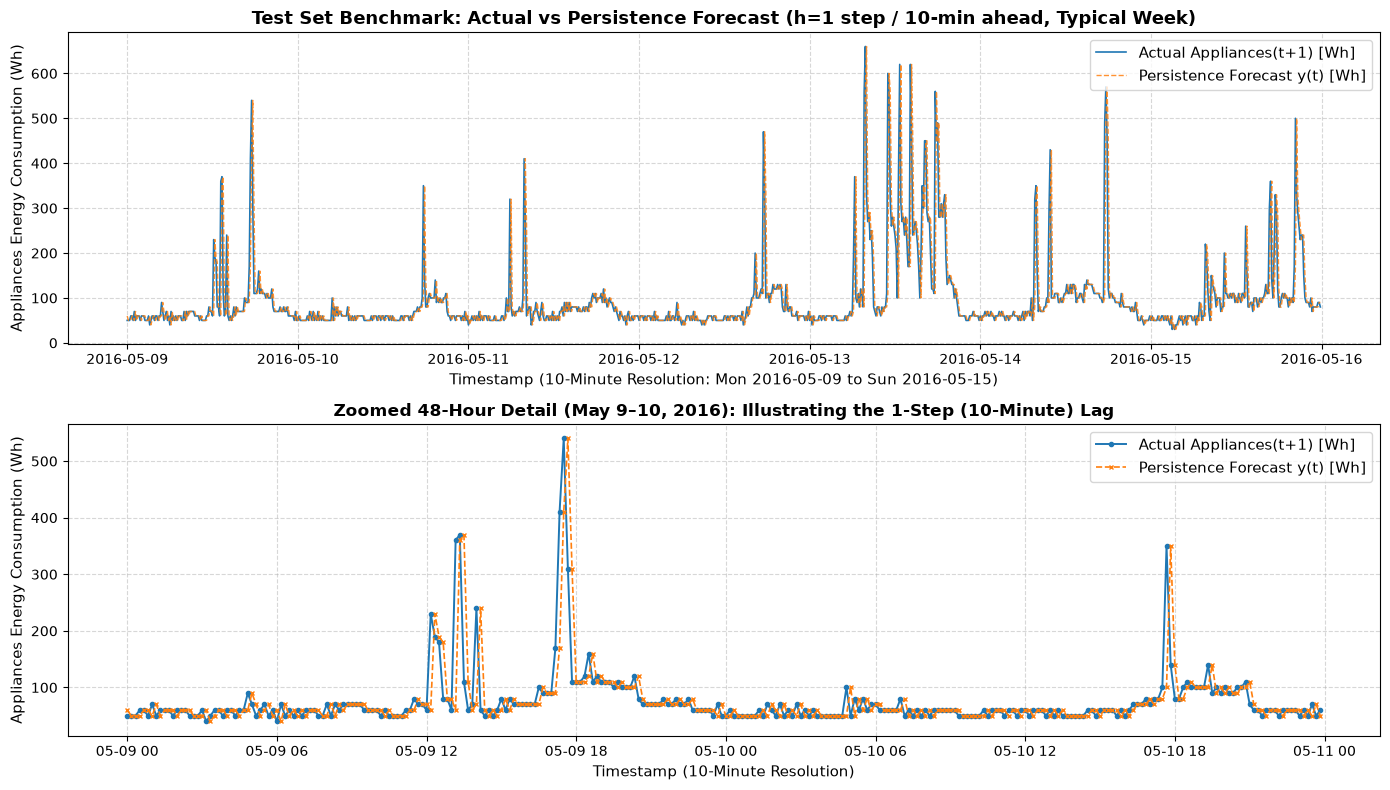

In [20]:
# -------------------------------------------------------------------
# Step 4: Plot Persistence vs Actual for One Test-Set Week (h=1)
# -------------------------------------------------------------------
# Select a representative 7-day period from the test set:
# Monday 2016-05-09 00:00:00 to Sunday 2016-05-15 23:50:00 (1,008 10-minute intervals)
week_start = pd.Timestamp("2016-05-09 00:00:00")
week_end = pd.Timestamp("2016-05-15 23:50:00")

test_h1_data = prepare_split_targets(test_df, h=1)
week_mask = (test_h1_data["date"] >= week_start) & (test_h1_data["date"] <= week_end)
week_data = test_h1_data[week_mask].copy()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

# Top Subplot: Full 7-Day Test Week
axes[0].plot(week_data["date"], week_data["target"], color="#1f77b4", linewidth=1.2, label="Actual Appliances(t+1) [Wh]")
axes[0].plot(week_data["date"], week_data["Appliances"], color="#ff7f0e", linewidth=1.0, linestyle="--", alpha=0.85, label="Persistence Forecast y(t) [Wh]")
axes[0].set_title("Test Set Benchmark: Actual vs Persistence Forecast (h=1 step / 10-min ahead, Typical Week)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Timestamp (10-Minute Resolution: Mon 2016-05-09 to Sun 2016-05-15)", fontsize=11)
axes[0].set_ylabel("Appliances Energy Consumption (Wh)", fontsize=11)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(loc="upper right", fontsize=11)

# Bottom Subplot: Zoomed 48-Hour Detail (May 9–10, 2016)
zoom_mask = (week_data["date"] >= "2016-05-09") & (week_data["date"] <= "2016-05-10 23:50:00")
zoom_data = week_data[zoom_mask]

axes[1].plot(zoom_data["date"], zoom_data["target"], color="#1f77b4", marker="o", markersize=3, linewidth=1.4, label="Actual Appliances(t+1) [Wh]")
axes[1].plot(zoom_data["date"], zoom_data["Appliances"], color="#ff7f0e", marker="x", markersize=3, linewidth=1.2, linestyle="--", label="Persistence Forecast y(t) [Wh]")
axes[1].set_title("Zoomed 48-Hour Detail (May 9–10, 2016): Illustrating the 1-Step (10-Minute) Lag", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Timestamp (10-Minute Resolution)", fontsize=11)
axes[1].set_ylabel("Appliances Energy Consumption (Wh)", fontsize=11)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(loc="upper right", fontsize=11)

plt.tight_layout()
fig_persist_path = FIG_DIR / "06_persistence_vs_actual_test_week_h1.png"
plt.savefig(fig_persist_path, dpi=150)
print(f"Saved figure: {fig_persist_path}")


## Baseline Results Analysis & Key Findings

| Horizon | Baseline | Val MAE (Wh) | Val RMSE (Wh) | Val R² | Test MAE (Wh) | Test RMSE (Wh) | Test R² |
|---|---|:---:|:---:|:---:|:---:|:---:|:---:|
| **h=1 (10-min)** | **Persistence** | **26.16** | **66.44** | **0.4813** | **26.75** | **66.85** | **0.4590** |
| h=1 (10-min) | Same Time Yesterday | 53.32 | 115.40 | -0.5647 | 52.51 | 109.49 | -0.4513 |
| h=1 (10-min) | Train-Mean | 53.98 | 92.41 | -0.0034 | 52.83 | 90.90 | -0.0004 |
| h=1 (10-min) | Mean by (hour, is_weekend) | 48.51 | 87.23 | 0.1060 | 47.90 | 85.75 | 0.1098 |
| **h=6 (1-hour)** | **Persistence** | **51.58** | **111.45** | **-0.4609** | **46.37** | **101.76** | **-0.2520** |
| h=6 (1-hour) | Same Time Yesterday | 53.24 | 115.38 | -0.5657 | 52.59 | 109.58 | -0.4519 |
| h=6 (1-hour) | Train-Mean | 53.94 | 92.38 | -0.0036 | 52.85 | 90.96 | -0.0004 |
| h=6 (1-hour) | Mean by (hour, is_weekend) | 48.47 | 87.21 | 0.1057 | 47.97 | 85.82 | 0.1095 |

### Side-by-Side Comparison at Horizon h=6 (1-Hour Ahead):

| Model Baseline | Val MAE (Wh) | Val RMSE (Wh) | Val R² | Test MAE (Wh) | Test RMSE (Wh) | Test R² |
|---|:---:|:---:|:---:|:---:|:---:|:---:|
| **Persistence** | 51.58 | 111.45 | -0.4609 | **46.37** | 101.76 | -0.2520 |
| **Mean by (hour, is_weekend)** | **48.47** | **87.21** | **0.1057** | 47.97 | **85.82** | **0.1095** |

**Divergence in Evaluation Metrics:**  

Persistence has lower test MAE (46.37 Wh vs. 47.97 Wh) but higher validation MAE (51.58 Wh vs. 48.47 Wh) than the hour-of-day baseline. Meanwhile, the hour-of-day baseline achieves a lower RMSE on both splits (Validation: 87.21 Wh vs. 111.45 Wh; Test: 85.82 Wh vs. 101.76 Wh) and higher R² on both splits (Validation: 0.1057 vs. -0.4609; Test: 0.1095 vs. -0.2520).

### Key Takeaways for Project Review 1:

1. **Persistence Dominates at 10 Minutes ($h=1$):**  

   At a 10-minute horizon, persistence achieves a test MAE of 26.75 Wh and an $R^2$ of 0.4590, substantially outperforming the naive train-mean (test MAE: 52.83 Wh, $R^2$: -0.0004). Whole-house total electricity consumption exhibits strong short-term temporal autocorrelation from domestic activities spanning multiple consecutive 10-minute intervals. Consequently, beating persistence at $h=1$ will be a stringent benchmark for machine learning models.

2. **Empirical Verification of the 'Spike Carried Forward' Phenomenon ($h=6$ vs. $h=1$):**  

   At $h=1$, for test rows where $\text{Appliances}(t) \ge 300$ Wh, the median consumption 10 minutes later remains high at **290.00 Wh** (mean: **329.55 Wh**), with only **2.99% (4 / 134)** dropping below 100 Wh, and only **17 spikes** are missed from baseline.  

   In contrast, at $h=6$, when a spike ($\ge 300$ Wh) is carried forward, median consumption 1 hour later falls sharply to **130.00 Wh** (mean: **186.24 Wh**), with **21.05% (28 / 133)** of rows dropping below 100 Wh back toward baseline. Furthermore, persistence completely misses **50 spikes** where usage jumped from $< 100$ Wh at time $t$ to $\ge 300$ Wh at $t+6$.  

   Because squared error squares these large individual discrepancies ($> 150$ Wh residuals), carrying spikes forward and missing newly ignited spikes heavily inflates RMSE to **101.76 Wh** and drives $R^2$ negative (**-0.2520**), even while test MAE (**46.37 Wh**) beats the train mean (**52.85 Wh**).

3. **Why Same-Time-Yesterday Yields Near-Identical Results at $h=1$ and $h=6$:**  

   For any given target timestamp $T$, the same-time-yesterday baseline produces the exact same prediction: the observed whole-house reading from 24 hours prior ($\text{Appliances}$ at $T - 24\text{h}$). Whether that forecast is evaluated at $h=1$ ($t = T - 10\text{min}$) or at $h=6$ ($t = T - 60\text{min}$), the prediction for timestamp $T$ is identical.  

   The only reason the aggregate metrics vary slightly (Test MAE: 52.51 Wh at $h=1$ vs. 52.59 Wh at $h=6$; Test RMSE: 109.49 Wh vs. 109.58 Wh) is because the $h=6$ split drops 5 additional boundary rows at the very end of the partition (2,960 rows for $h=1$ vs. 2,955 rows for $h=6$).

4. **Diurnal Pattern Baseline & Hypothesis for Review 2:**  

   The 4th baseline, Mean by (hour of day, is_weekend) computed on the training set, achieves consistent test performance across both horizons (Test MAE: 47.90 Wh at $h=1$, 47.97 Wh at $h=6$, with positive $R^2 \approx 0.11$). At 1 hour, it achieves a lower RMSE (85.82 Wh) than both persistence (101.76 Wh) and train-mean (90.96 Wh).  

   This suggests that while short-term autocorrelation fades over 60 minutes, time-of-day conditioning provides a stable baseline. This forms a concrete hypothesis to test in Review 2: whether gradient-boosted trees and autoregressive lag features can effectively blend short-term momentum with diurnal schedule patterns to outperform persistence at both horizons.
